# TC5061 · Actividad 3 — Notebook de exploración de datos

Alumno: Diego Falcón Costilla · Matrícula: A01139580
Curso: TC5061.10 · Modalidad: Individual

Este notebook conserva únicamente la exploración del dataset Diamonds de Kaggle (<https://www.kaggle.com/datasets/shivam2503/diamonds>) y el razonamiento detrás de cada decisión de limpieza. La carga, la limpieza, la división, el entrenamiento, la evaluación y el registro en MLflow se migraron al script `src/train.py`, que aplica exactamente las mismas reglas de limpieza en la función `clean_data` y se ejecuta desde la línea de comandos (ver `README.md`).

## Contenido
1. Carga y descripción del dataset
2. Análisis exploratorio (EDA)
3. Limpieza de datos y selección de variables (justificación de las reglas que implementa `clean_data`)


## 0. Configuración del entorno
Se fijan la semilla y las rutas para que el notebook sea reproducible.

In [1]:
# Librerías estándar
import warnings
from pathlib import Path

# Librerías de análisis y visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

# Semilla global: garantiza que la división train/test y los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Rutas del proyecto (el notebook vive en notebooks/, los datos en data/)
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "raw" / "diamonds.csv"

print(f"pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Directorio base: {BASE_DIR}")

pandas 3.0.5 | seaborn 0.13.2
Directorio base: C:\Users\diego\projects\aprendizajeautomatico\actividad-03-codigodeexperimentación


## 1. Carga y descripción del dataset

In [2]:
# Carga del CSV original (sin modificar)
df_raw = pd.read_csv(DATA_PATH)

print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 53,936 | Variables: 10


,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.230,Ideal,E,SI2,61.500,55.000,3.950,3.980,2.430,326
1,0.210,Premium,E,SI1,59.800,61.000,3.890,3.840,2.310,326
2,0.230,Good,E,VS1,56.900,65.000,4.050,4.070,2.310,327
3,0.290,Premium,I,VS2,62.400,58.000,4.200,4.230,2.630,334
4,0.310,Good,J,SI2,63.300,58.000,4.340,4.350,2.750,335


In [3]:
# Estructura: tipo de dato, valores no nulos y valores únicos por columna
estructura = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "no_nulos": df_raw.notna().sum(),
    "nulos": df_raw.isna().sum(),
    "valores_unicos": df_raw.nunique(),
})
estructura

,tipo,no_nulos,nulos,valores_unicos
carat,float64,53936,0,271
cut,str,53936,0,5
color,str,53936,0,7
clarity,str,53936,0,8
depth,float64,53936,0,184
table,float64,53936,0,127
x,float64,53936,0,551
y,float64,53936,0,551
z,float64,53936,0,372
price,int64,53936,0,11600


### Diccionario de variables

| Variable | Tipo | Significado |
|---|---|---|
| `carat` | numérica continua | Peso del diamante en quilates (1 quilate = 0.2 g). |
| `cut` | categórica ordinal | Calidad del corte, de peor a mejor: `Fair`, `Good`, `Very Good`, `Premium`, `Ideal`. |
| `color` | categórica ordinal | Color según la escala GIA, de peor a mejor: `J`, `I`, `H`, `G`, `F`, `E`, `D` (D es incoloro). |
| `clarity` | categórica ordinal | Claridad (inclusiones), de peor a mejor: `I1`, `SI2`, `SI1`, `VS2`, `VS1`, `VVS2`, `VVS1`, `IF`. |
| `depth` | numérica (%) | Profundidad total: altura entre el diámetro promedio, `z / mean(x, y) × 100`. |
| `table` | numérica (%) | Ancho de la faceta superior (mesa) relativo al punto más ancho. |
| `x` | numérica (mm) | Largo. |
| `y` | numérica (mm) | Ancho. |
| `z` | numérica (mm) | Altura. |
| `price` | numérica entera (objetivo) | Precio en USD. |

Observaciones iniciales
- 53,936 registros y 10 variables: 7 numéricas y 3 categóricas.
- No hay valores nulos explícitos, pero eso no significa que no falten datos: hay que revisar valores imposibles como medidas en cero.
- `cut`, `color` y `clarity` se leyeron como texto. Son escalas con un orden natural, así que deben tratarse como categóricas ordenadas.
- `depth` es una variable calculada a partir de `x`, `y` y `z`, lo cual permite verificar la consistencia de las medidas.

## 2. Análisis exploratorio (EDA)
### 2.1 Estadísticas descriptivas

In [4]:
# Estadísticas descriptivas de las variables numéricas (con percentiles extremos para detectar colas)
df_raw.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
carat,"53,936.000",0.798,0.473,0.200,0.240,0.400,0.700,1.040,2.180,4.500
depth,"53,936.000",61.749,1.433,43.000,57.900,61.000,61.800,62.500,65.600,79.000
table,"53,936.000",57.457,2.234,43.000,53.000,56.000,57.000,59.000,64.000,95.000
x,"53,936.000",5.731,1.121,0.000,4.020,4.710,5.700,6.540,8.350,10.230
y,"53,936.000",5.734,1.142,0.000,4.040,4.720,5.710,6.540,8.330,58.900
z,"53,936.000",3.539,0.705,0.000,2.480,2.910,3.530,4.040,5.150,31.800
price,"53,936.000","3,931.903","3,988.214",326.000,429.000,950.000,"2,401.000","5,324.000","17,375.950","18,823.000"


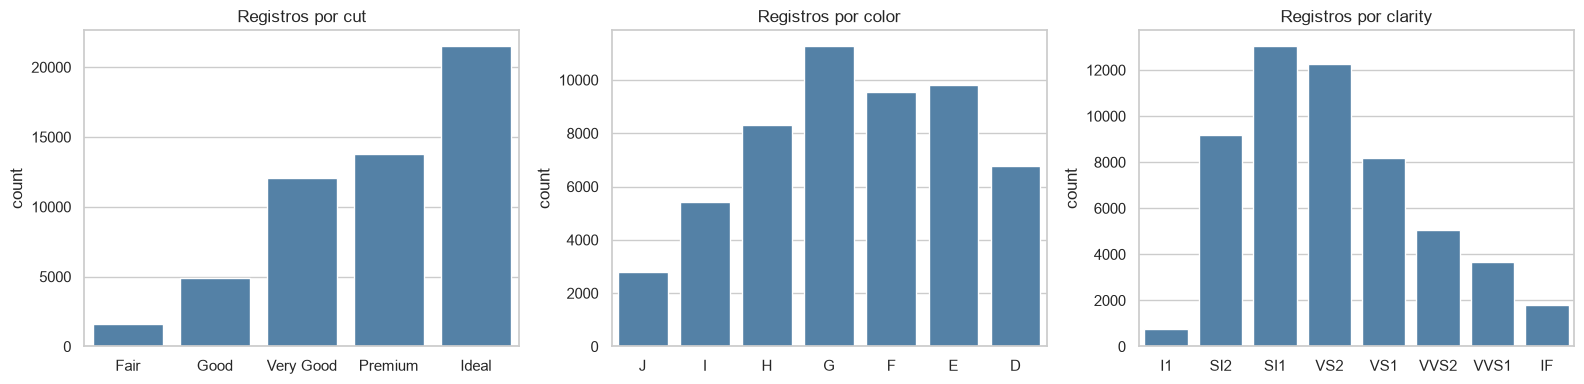

In [5]:
# Orden natural de las escalas de calidad (de peor a mejor), definido por el GIA
ORDEN = {
    "cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
    "color": ["J", "I", "H", "G", "F", "E", "D"],
    "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
}

# Distribución de cada variable categórica
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ORDEN):
    sns.countplot(data=df_raw, x=col, order=ORDEN[col], ax=ax, color="steelblue")
    ax.set_title(f"Registros por {col}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Lectura de las estadísticas
- `price` va de 326 a 18,823 USD, con una media (3,932) muy por encima de la mediana (2,401): la distribución está fuertemente sesgada a la derecha.
- `carat` también está sesgado: la mitad de los diamantes pesa 0.7 quilates o menos, pero el máximo es 4.5.
- `x`, `y` y `z` tienen mínimo 0, lo cual es físicamente imposible, y `y` y `z` tienen máximos de 58.9 y 31.8 mm, cuando el percentil 99 es de apenas 8.3 y 5.2 mm. Son errores de captura.
- `depth` y `table` están muy concentrados (desviación de 1.4 y 2.2 puntos) pero con extremos lejanos (43 a 79 y 43 a 95).
- Las categorías están desbalanceadas: casi 40 % de los diamantes tiene corte `Ideal` y sólo 3 % `Fair`; en claridad, `I1` apenas tiene 739 registros (1.4 %).

### 2.2 Distribuciones de las variables numéricas

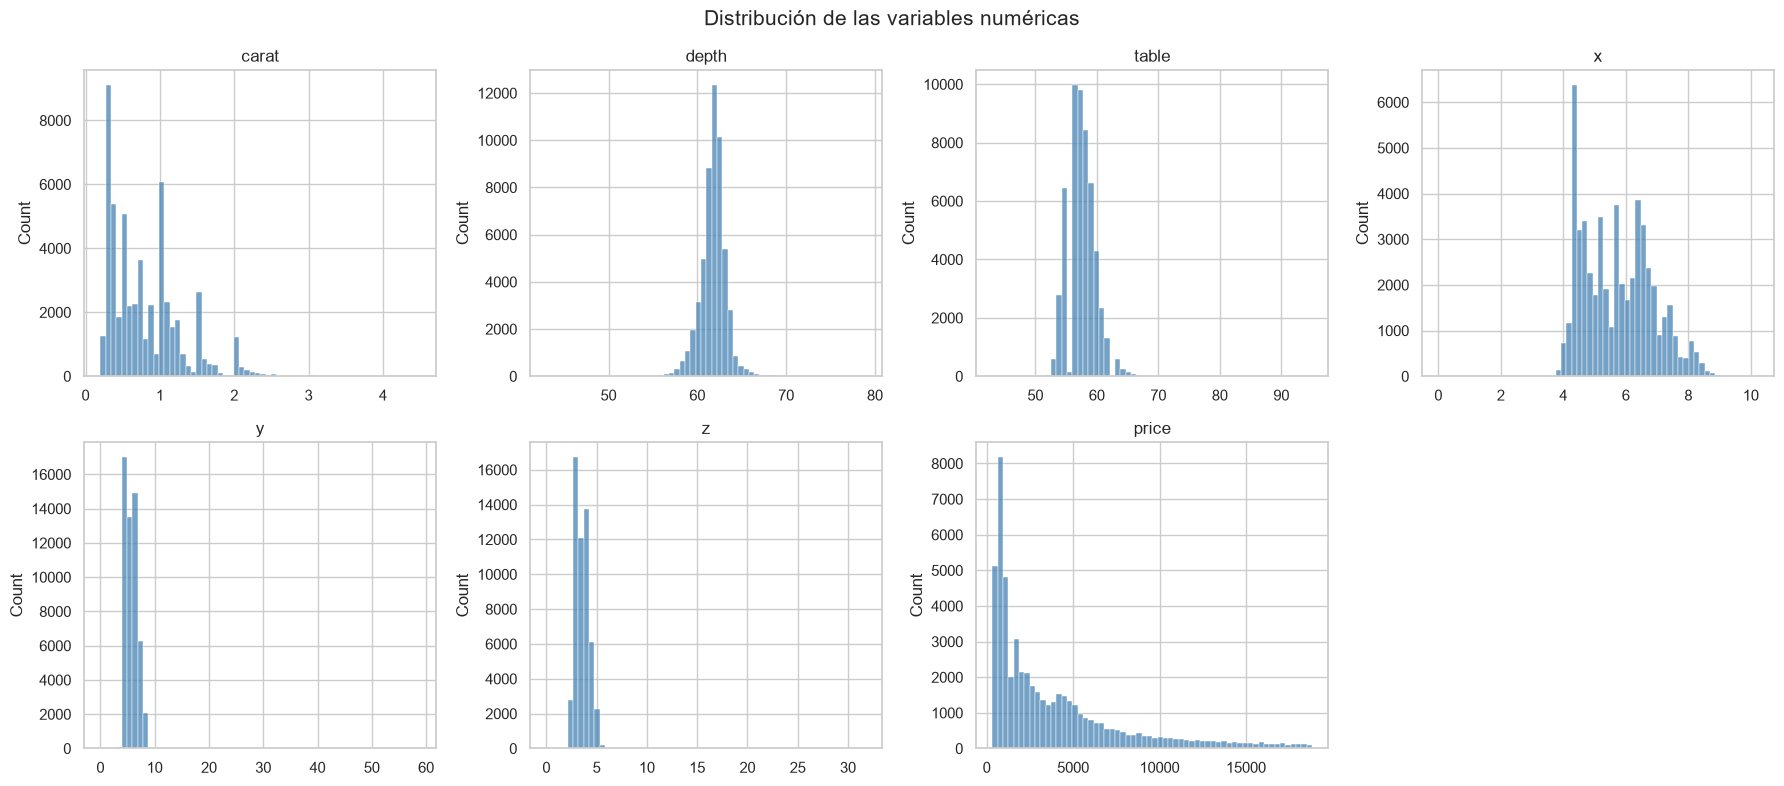

In [6]:
# Histograma de cada variable numérica para ver forma, sesgo y valores extremos
num_cols = df_raw.select_dtypes("number").columns
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[col], bins=60, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].set_visible(False)
fig.suptitle("Distribución de las variables numéricas", fontsize=15)
plt.tight_layout()
plt.show()

- `price` y `carat` tienen sesgo a la derecha: muchos diamantes pequeños y baratos, y pocos grandes y caros.
- `carat` muestra picos en valores redondos (0.3, 0.5, 0.7, 1.0, 1.5, 2.0): los diamantes se tallan buscando llegar a esos pesos porque el mercado los valora más.
- Los histogramas de `y` y `z` se ven comprimidos a la izquierda por culpa de unos pocos valores absurdos, otra señal de errores de captura.

### 2.3 Variable objetivo

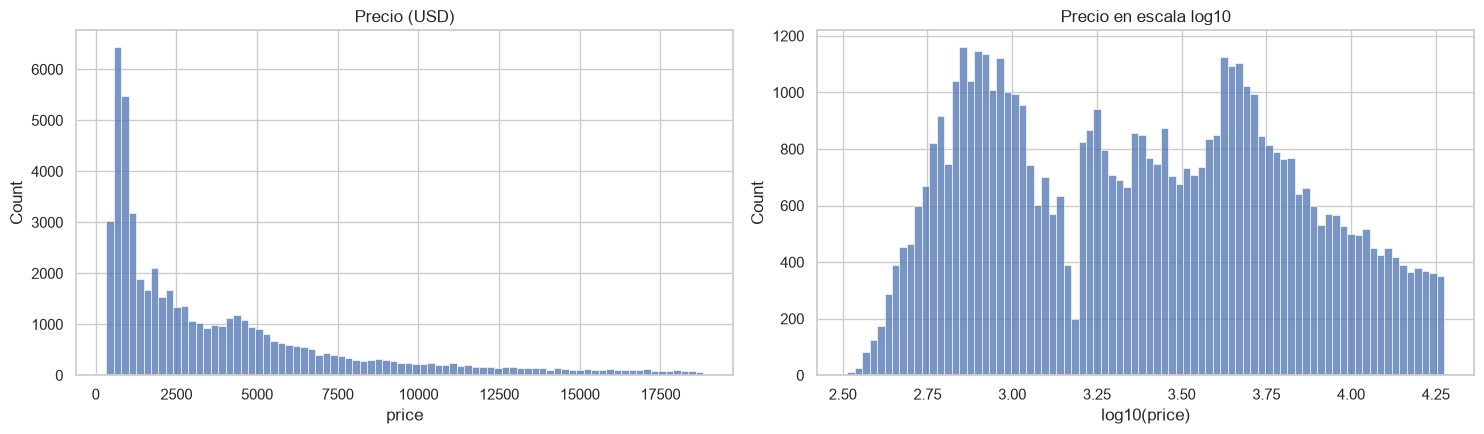

Media: 3,932 USD | Mediana: 2,401 USD | Asimetría: 1.62


In [7]:
# El precio está muy sesgado; en escala logarítmica se ve su forma real
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df_raw["price"], bins=80, ax=axes[0])
axes[0].set(title="Precio (USD)", xlabel="price")
sns.histplot(np.log10(df_raw["price"]), bins=80, ax=axes[1])
axes[1].set(title="Precio en escala log10", xlabel="log10(price)")
plt.tight_layout()
plt.show()

print(f"Media: {df_raw['price'].mean():,.0f} USD | Mediana: {df_raw['price'].median():,.0f} USD | Asimetría: {df_raw['price'].skew():.2f}")

El precio tiene una asimetría de 1.62. En escala logarítmica la distribución es multimodal, con concentraciones alrededor de 800, 2,000 y 4,500 USD, lo que sugiere segmentos de mercado distintos. Un modelo lineal sobre el precio en USD tendrá más dificultad con esta forma; transformar el objetivo con logaritmo es una mejora natural para iteraciones futuras, pero se mantiene el precio original en el baseline para que las métricas queden en USD y sean fáciles de interpretar.

### 2.4 Relación entre variables

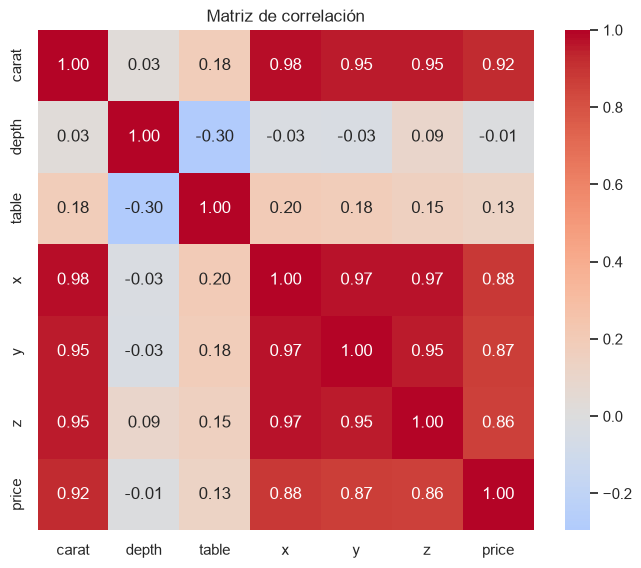

,corr_con_objetivo
carat,0.922
x,0.884
y,0.865
z,0.861
table,0.127
depth,-0.011


In [8]:
# Matriz de correlación de Pearson entre las variables numéricas
corr = df_raw.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

corr["price"].drop("price").sort_values(ascending=False).to_frame("corr_con_objetivo")

- `carat` es la variable más correlacionada con el precio (r = 0.92). `x`, `y` y `z` también lo están (0.86 a 0.88), pero porque miden el tamaño de la piedra igual que `carat`.
- `depth` (r = −0.01) y `table` (r = 0.13) casi no tienen relación lineal con el precio.
- `carat`, `x`, `y` y `z` están casi perfectamente correlacionadas entre sí: esto es multicolinealidad y se atiende en la selección de variables.

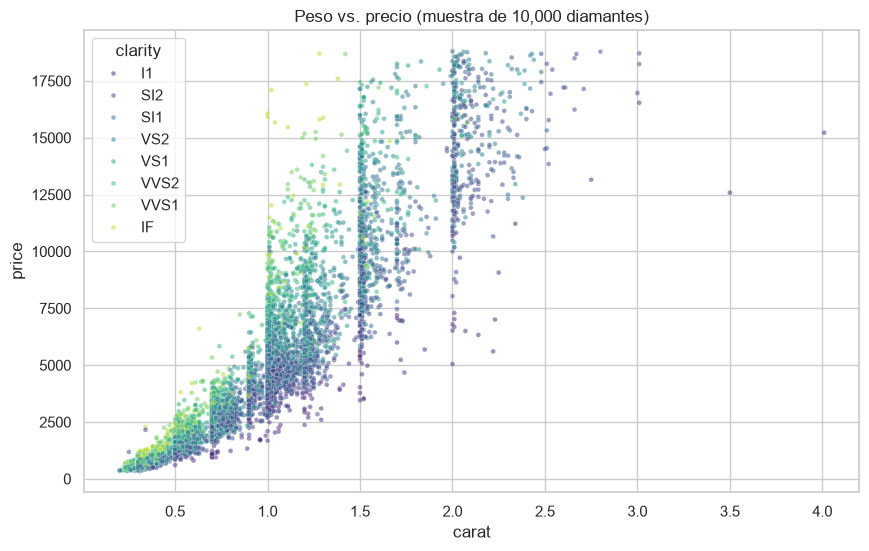

In [9]:
# Relación peso–precio, coloreada por claridad
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_raw.sample(10_000, random_state=SEED), x="carat", y="price", hue="clarity",
                hue_order=ORDEN["clarity"], palette="viridis", alpha=0.5, s=12, ax=ax)
ax.set_title("Peso vs. precio (muestra de 10,000 diamantes)")
plt.show()

- La relación entre peso y precio es creciente pero no lineal: el precio crece más rápido que el peso (un diamante de 2 quilates vale mucho más que dos de 1 quilate). Una recta no podrá capturar esta curvatura por completo.
- A un mismo peso, los diamantes con mejor claridad están arriba: la calidad explica parte de la dispersión vertical.
- Se ven columnas verticales en los pesos redondos y un techo cerca de 18,800 USD, el precio máximo del dataset.

### 2.5 Calidad y precio: el efecto del peso

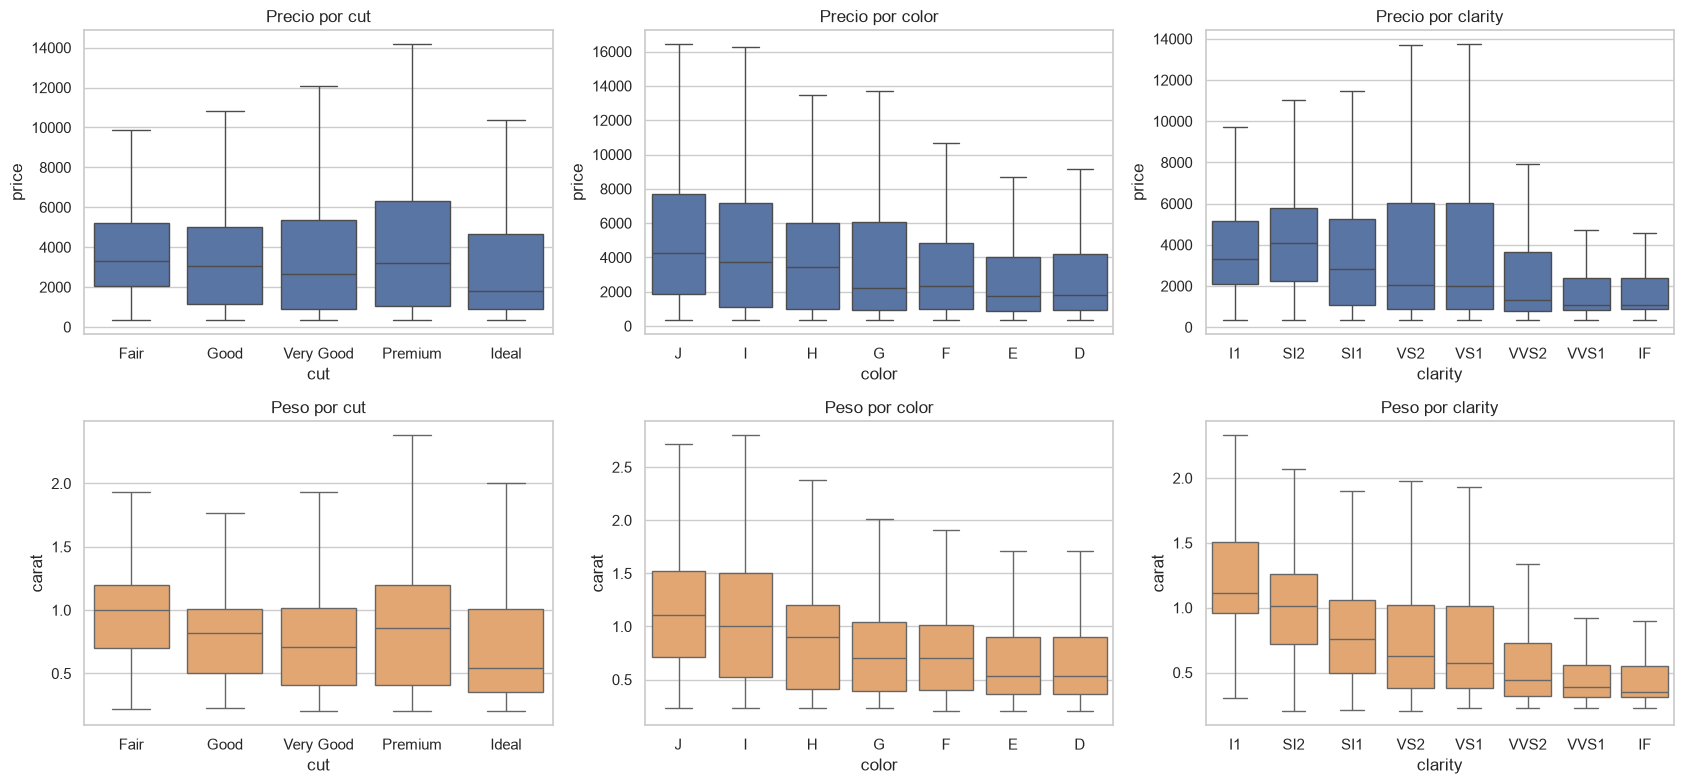

In [10]:
# Precio mediano y peso mediano por categoría de calidad
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for i, col in enumerate(ORDEN):
    sns.boxplot(data=df_raw, x=col, y="price", order=ORDEN[col], ax=axes[0, i], showfliers=False)
    axes[0, i].set_title(f"Precio por {col}")
    sns.boxplot(data=df_raw, x=col, y="carat", order=ORDEN[col], ax=axes[1, i], showfliers=False, color="sandybrown")
    axes[1, i].set_title(f"Peso por {col}")
plt.tight_layout()
plt.show()

A primera vista los resultados contradicen la intuición: los diamantes de corte `Ideal`, color `D` y claridad `IF` (las mejores categorías) tienen los precios medianos más bajos. La fila inferior explica por qué: esas mismas categorías tienen los diamantes más pequeños (peso mediano de 0.54, 0.53 y 0.35 quilates, frente a 1.0 o más en las peores). Las piedras grandes rara vez son perfectas.

Esto es un ejemplo de variable de confusión: el peso domina el precio y oculta el efecto de la calidad. Por eso el modelo debe incluir `carat` y la calidad al mismo tiempo; sólo así cada coeficiente mide el efecto de la calidad a peso constante.

## 3. Limpieza de datos
Se revisan en orden: tipos incorrectos, duplicados, valores faltantes y outliers. Cada decisión se documenta con su justificación. Se trabaja sobre una copia para conservar `df_raw` intacto.

In [11]:
# Copia de trabajo y bitácora de limpieza (registros antes/después de cada paso)
df = df_raw.copy()
bitacora = [("Dataset original", len(df))]

### 3.1 Tipos de datos

In [12]:
# cut, color y clarity se leen como texto; se convierten a categóricas con su orden natural
for col, niveles in ORDEN.items():
    df[col] = pd.Categorical(df[col], categories=niveles, ordered=True)

# Verificación: ningún valor quedó fuera de las categorías esperadas (aparecería como NaN)
print("Valores fuera de categoría:", {c: int(df[c].isna().sum()) for c in ORDEN})
print("Valores negativos en variables numéricas:", int((df.select_dtypes('number') < 0).sum().sum()))
df.dtypes.to_frame("tipo")

Valores fuera de categoría: {'cut': 0, 'color': 0, 'clarity': 0}
Valores negativos en variables numéricas: 0


,tipo
carat,float64
cut,category
color,category
clarity,category
depth,float64
table,float64
x,float64
y,float64
z,float64
price,int64


Decisión: `cut`, `color` y `clarity` pasan a `category` con orden explícito según la escala del GIA. Así las gráficas y la codificación respetan el orden de peor a mejor, y cualquier valor mal escrito aparecería como nulo (no hay ninguno). Las variables numéricas ya tienen el tipo correcto y no hay negativos.

### 3.2 Duplicados

In [13]:
# Duplicados exactos y registros con las mismas características pero distinto precio
dup_exactos = df.duplicated().sum()
dup_features = df.drop(columns="price").duplicated().sum()
print(f"Duplicados exactos: {dup_exactos}")
print(f"Registros con mismas características (incluye los exactos): {dup_features}")
df[df.duplicated(keep=False)].sort_values(["carat", "price"]).head(6)

Duplicados exactos: 146
Registros con mismas características (incluye los exactos): 345


,carat,cut,color,clarity,depth,table,x,y,z,price
43991,0.300,Good,J,VS1,63.400,57.000,4.230,4.260,2.690,394
47292,0.300,Good,J,VS1,63.400,57.000,4.230,4.260,2.690,394
31620,0.300,Ideal,H,SI1,62.200,57.000,4.260,4.290,2.660,450
31622,0.300,Ideal,H,SI1,62.200,57.000,4.270,4.280,2.660,450
31623,0.300,Ideal,H,SI1,62.200,57.000,4.260,4.290,2.660,450
31625,0.300,Ideal,H,SI1,62.200,57.000,4.270,4.280,2.660,450


In [14]:
# Se eliminan los duplicados exactos, conservando la primera aparición
df = df.drop_duplicates().reset_index(drop=True)
bitacora.append(("Sin duplicados exactos", len(df)))
print(f"Registros: {len(df):,}")

Registros: 53,790


Decisión: se eliminan los 146 duplicados exactos. Con 10 variables, varias de ellas con dos decimales, es muy poco probable que dos diamantes distintos coincidan en todo, incluido el precio; lo más probable es que sea el mismo diamante capturado dos veces. Conservarlos daría más peso a esos casos y, si una copia cae en entrenamiento y otra en prueba, el modelo sería evaluado con datos que ya vio (data leakage).

Los registros con las mismas características pero distinto precio se conservan: pueden ser diamantes distintos con medidas parecidas, y la variación de precio entre ellos es información real del mercado.

### 3.3 Valores faltantes

In [15]:
# No hay NaN, pero una medida de 0 mm es imposible en un diamante: es un faltante disfrazado
print("Nulos explícitos:", int(df.isna().sum().sum()))
ceros = (df[["x", "y", "z"]] == 0)
print("Ceros por dimensión:", ceros.sum().to_dict())
print("Diamantes con al menos una dimensión en 0:", int(ceros.any(axis=1).sum()))
df[ceros.any(axis=1)].head(8)

Nulos explícitos: 0
Ceros por dimensión: {'x': 7, 'y': 6, 'z': 19}
Diamantes con al menos una dimensión en 0: 19


,carat,cut,color,clarity,depth,table,x,y,z,price
2201,1.000,Premium,G,SI2,59.100,59.000,6.550,6.480,0.000,3142
2308,1.010,Premium,H,I1,58.100,59.000,6.660,6.600,0.000,3167
4778,1.100,Premium,G,SI2,63.000,59.000,6.500,6.470,0.000,3696
5457,1.010,Premium,F,SI2,59.200,58.000,6.500,6.470,0.000,3837
10145,1.500,Good,G,I1,64.000,61.000,7.150,7.040,0.000,4731
11156,1.070,Ideal,F,SI2,61.600,56.000,0.000,6.620,0.000,4954
11935,1.000,Very Good,H,VS2,63.300,53.000,0.000,0.000,0.000,5139
13570,1.150,Ideal,G,VS2,59.200,56.000,6.880,6.830,0.000,5564


In [16]:
# Se eliminan los registros con alguna dimensión en cero
df = df[(df[["x", "y", "z"]] > 0).all(axis=1)].reset_index(drop=True)
bitacora.append(("Sin dimensiones en cero (x, y o z = 0)", len(df)))
print(f"Registros: {len(df):,}")

Registros: 53,771


Decisión: 19 diamantes (0.04 %) tienen al menos una dimensión en 0 mm después de quitar duplicados. Son faltantes disfrazados: el dato no se capturó y se guardó como cero.

- Se eliminan en lugar de imputarse: son muy pocos, por lo que no se pierde información relevante, e imputar una medida física con la mediana generaría diamantes con proporciones inventadas.
- Se deja la revisión de nulos explícitos en el notebook para que el flujo siga siendo válido si el dataset se actualiza.

### 3.4 Outliers

In [17]:
# Detección de outliers con el criterio IQR (1.5 × rango intercuartílico)
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()

pd.Series({c: outliers_iqr(df[c]) for c in ["carat", "depth", "table", "x", "y", "z", "price"]},
          name="outliers_IQR").to_frame()

,outliers_IQR
carat,1863
depth,2522
table,603
x,22
y,20
z,26
price,3518


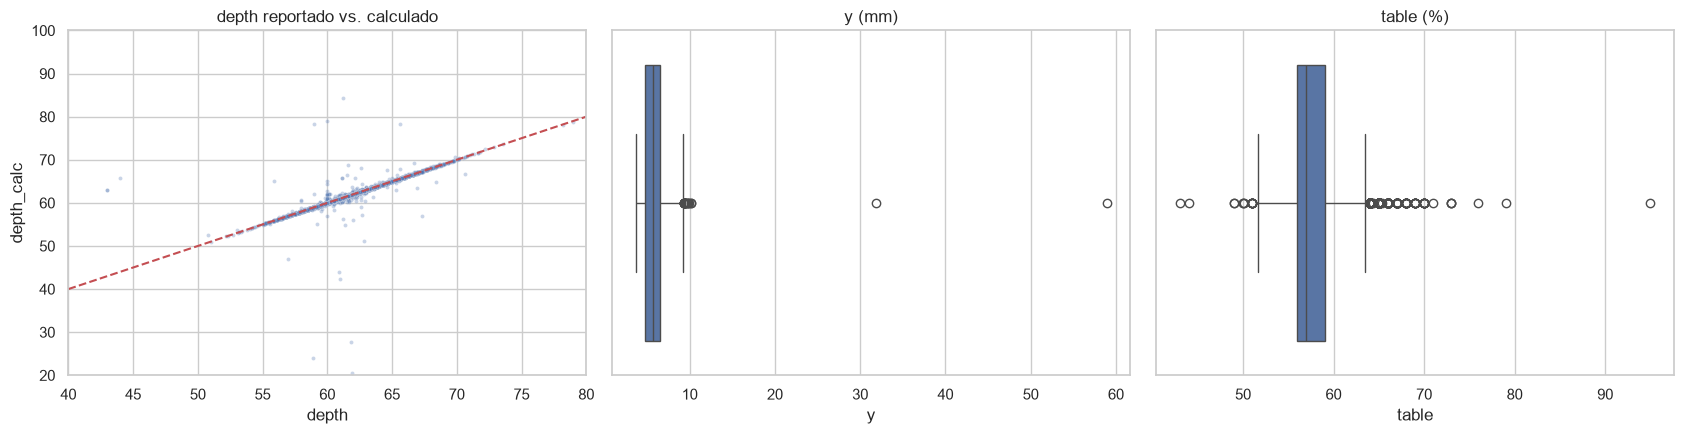

Diamantes con depth inconsistente (> 5 puntos de diferencia): 27


,carat,x,y,z,depth,depth_calc,price
14594,1.100,6.600,6.700,1.100,60.600,16.100,5909
21600,1.400,7.300,7.200,1.400,60.700,19.400,9752
20642,1.500,7.400,7.500,1.500,61.900,20.500,8971
24003,2.000,8.100,58.900,8.100,58.900,24.100,12210
49026,0.500,5.200,31.800,5.100,61.800,27.700,2075
46977,0.600,5.300,5.300,2.200,61.000,42.300,1831
39102,0.400,4.700,4.700,2.100,60.900,43.900,1068
32990,0.300,6.600,4.600,2.600,57.000,46.900,816
2932,1.000,6.300,6.200,3.200,62.800,51.200,3293
38595,0.400,4.600,4.600,2.500,61.400,54.900,1043


In [18]:
# Consistencia geométrica: depth debe ser igual a z / promedio(x, y) × 100
df["depth_calc"] = df["z"] / ((df["x"] + df["y"]) / 2) * 100
df["depth_diff"] = (df["depth_calc"] - df["depth"]).abs()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="depth", y="depth_calc", s=8, alpha=0.3, ax=axes[0])
axes[0].plot([40, 80], [40, 80], "r--")
axes[0].set(xlim=(40, 80), ylim=(20, 100), title="depth reportado vs. calculado")
sns.boxplot(x=df["y"], ax=axes[1]); axes[1].set_title("y (mm)")
sns.boxplot(x=df["table"], ax=axes[2]); axes[2].set_title("table (%)")
plt.tight_layout()
plt.show()

print("Diamantes con depth inconsistente (> 5 puntos de diferencia):", int((df["depth_diff"] > 5).sum()))
df[df["depth_diff"] > 5][["carat", "x", "y", "z", "depth", "depth_calc", "price"]].sort_values("depth_calc").round(1)

El criterio IQR marca 3,518 precios y 1,863 pesos como outliers, pero son diamantes grandes y caros reales: el sesgo de estas variables es natural. Eliminar todo lo que marca el IQR borraría justamente los casos más valiosos. Por eso se toman decisiones caso por caso, usando la consistencia geométrica como criterio objetivo:

| Problema | Registros | Decisión | Justificación |
|---|---|---|---|
| `depth` reportado no coincide con el calculado a partir de `x`, `y`, `z` (diferencia > 5 puntos) | 27 | Eliminar | Al menos una medida está mal capturada (por ejemplo `y` = 58.9 mm o `z` = 31.8 mm en diamantes de 0.5 a 2 quilates). No se sabe cuál de los valores es el correcto, así que no se puede corregir. |
| Precios y pesos altos marcados por IQR | 3,518 y 1,863 | Conservar | Son diamantes grandes reales; el modelo los necesita para aprender el segmento caro. |
| `depth` o `table` extremos pero geométricamente consistentes | 6 con depth fuera de 50 a 75; 8 con table > 70 | Conservar | Son tallas poco comunes pero posibles, y su efecto en un modelo con miles de registros es mínimo. |

El umbral de 5 puntos se eligió porque en la gráfica casi todos los diamantes están sobre la diagonal y los inconsistentes se separan claramente; diferencias menores pueden deberse al redondeo de las medidas.

In [19]:
# Se eliminan las geometrías inconsistentes y las columnas auxiliares de la verificación
df = df[df["depth_diff"] <= 5].drop(columns=["depth_calc", "depth_diff"]).reset_index(drop=True)
bitacora.append(("Sin geometría inconsistente (depth reportado vs. calculado > 5 puntos)", len(df)))

pd.DataFrame(bitacora, columns=["paso", "registros"]).assign(
    eliminados=lambda d: d["registros"].shift(1).fillna(d["registros"]).astype(int) - d["registros"]
)

,paso,registros,eliminados
0,Dataset original,53936,0
1,Sin duplicados exactos,53790,146
2,"Sin dimensiones en cero (x, y o z = 0)",53771,19
3,Sin geometría inconsistente (depth reportado v...,53744,27


### 3.5 Selección de variables
`x`, `y` y `z` miden lo mismo que `carat`: el tamaño de la piedra.

In [20]:
# Correlación entre las variables de tamaño en el dataset limpio
df[["carat", "x", "y", "z"]].corr().round(3)

,carat,x,y,z
carat,1.000,0.978,0.977,0.977
x,0.978,1.000,0.999,0.992
y,0.977,0.999,1.000,0.992
z,0.977,0.992,0.992,1.000


Decisión: se excluyen `x`, `y` y `z` del modelo y se conserva `carat`.

- Su correlación con `carat` es de 0.98 y entre ellas de 0.99: aportan casi la misma información.
- En una regresión lineal, la multicolinealidad hace que los coeficientes sean inestables y difíciles de interpretar. En una prueba incluyéndolas, el R² apenas subía de 0.912 a 0.915, pero `y` recibía un coeficiente de +3,900 USD y `z` uno de −5,200 USD, signos que no tienen sentido físico.
- `carat` es la medida que usa el mercado para fijar precios, así que es la más interpretable.

Su función en este notebook fue servir para la limpieza (detectar ceros y geometrías inconsistentes).

In [21]:
# Variables del modelo: peso, proporciones y las tres escalas de calidad
FEATURES_NUM = ["carat", "depth", "table"]
FEATURES_CAT = ["cut", "color", "clarity"]
TARGET = "price"
df = df[FEATURES_NUM + FEATURES_CAT + [TARGET]]

print(f"Dataset limpio: {df.shape[0]:,} registros × {df.shape[1]} columnas")
df.head()

Dataset limpio: 53,744 registros × 7 columnas


,carat,depth,table,cut,color,clarity,price
0,0.230,61.500,55.000,Ideal,E,SI2,326
1,0.210,59.800,61.000,Premium,E,SI1,326
2,0.230,56.900,65.000,Good,E,VS1,327
3,0.290,62.400,58.000,Premium,I,VS2,334
4,0.310,63.300,58.000,Good,J,SI2,335


## Siguiente paso: el script de entrenamiento
Las decisiones de esta exploración quedan implementadas en `src/train.py`: eliminación de duplicados exactos, de diamantes con alguna dimensión en cero y de geometrías inconsistentes (depth reportado frente al calculado con más de 5 puntos de diferencia), y exclusión de `x`, `y` y `z` del modelo por su colinealidad con `carat`. A partir de aquí, cualquier cambio de modelo o de hiperparámetros se hace con argumentos de línea de comandos y queda registrado en MLflow, no en celdas de este notebook.
